Step 1: Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

Step 2: Upload and load the dataset

2.1 Read the CSV file

In [3]:
df = pd.read_csv('IMDB Dataset.csv')

2.2 Display the first five records

In [4]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Step 3: Explore the dataset (EDA)

3.1 Check the number of rows and columns

In [5]:
df.shape

(50000, 2)

3.2 Check column names

In [6]:
df.columns

Index(['review', 'sentiment'], dtype='object')

3.3 Check data types

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


3.4 Check missing values

In [8]:
df.isnull().sum()

,0
review,0
sentiment,0


3.5 Check duplicate records

In [10]:
df.duplicated().sum()

np.int64(418)

Remove duplicates :

In [11]:
df.drop_duplicates(inplace = True)

3.6 Check sentiment distribution

In [12]:
df['sentiment'].value_counts()

,count
sentiment,
positive,24884
negative,24698


Visualize it:

In [14]:
import seaborn as sns

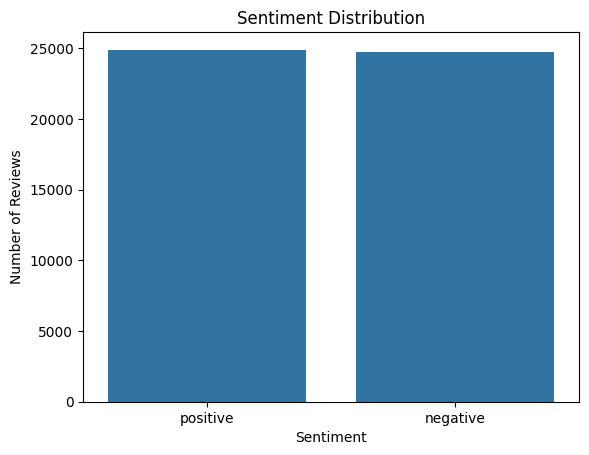

In [15]:
sns.countplot(data=df, x='sentiment')

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

Step 4: Convert sentiment labels into numerical values

In [16]:
df['sentiment'] = df['sentiment'].map({
    'positive': 1,
    'negative': 0
})

In [17]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


Step 5: Separate independent and dependent variables

In [18]:
X = df['review']
y = df['sentiment']

Step 6: Split the dataset into training and testing data

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=42,
    stratify=y
)

In [22]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24791,)
Testing data: (24791,)


Step 7: Tokenization

7.1 Define vocabulary size

In [23]:
vocab_size = 10000

7.2 Create the tokenizer

In [25]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [26]:
tokenizer = Tokenizer(num_words=vocab_size)

7.3 Fit the tokenizer on training reviews

In [27]:
tokenizer.fit_on_texts(X_train)

7.4 Convert text into integer sequences

In [28]:
X_train_sequences = tokenizer.texts_to_sequences(X_train)

X_test_sequences = tokenizer.texts_to_sequences(X_test)

Step 8: Padding sequences

8.1 Define maximum sequence length

In [29]:
max_length = 200

8.2 Apply padding

In [30]:
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [31]:
X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

8.3 Check the shapes

In [32]:
print("X_train shape:", X_train_padded.shape)
print("X_test shape:", X_test_padded.shape)

X_train shape: (24791, 200)
X_test shape: (24791, 200)


Step 9: Build the RNN model

9.1 Create a Sequential model

In [33]:
model = Sequential()

9.2 Add the Embedding layer

In [34]:
model.add(
    Embedding(
        input_dim=10000,
        output_dim=32,
        input_length=200
    )
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


9.3 Add the SimpleRNN layer

In [35]:
model.add(
    SimpleRNN(
        32,
        activation='tanh'
    )
)

9.4 Add the Dense output layer

In [36]:
model.add(
    Dense(
        1,
        activation='sigmoid'
    )
)

9.5 View the model architecture

In [37]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Step 10: Compile the model

In [38]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

Step 11: Train the RNN model

In [39]:
history = model.fit(
    X_train_padded,
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 14s 70ms/step - accuracy: 0.5040 - loss: 0.6938 - val_accuracy: 0.5150 - val_loss: 0.6933
Epoch 2/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.5755 - loss: 0.6761 - val_accuracy: 0.5146 - val_loss: 0.6947
Epoch 3/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.6403 - loss: 0.6081 - val_accuracy: 0.5989 - val_loss: 0.6825
Epoch 4/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - accuracy: 0.7153 - loss: 0.4915 - val_accuracy: 0.5084 - val_loss: 0.7943
Epoch 5/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.7602 - loss: 0.4138 - val_accuracy: 0.5051 - val_loss: 0.8847
Epoch 6/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.7912 - loss: 0.3682 - val_accuracy: 0.5066 - val_loss: 0.9403
Epoch 7/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - accuracy: 0.8169 - loss: 0.3411 - val_accuracy: 0.5164 - val_loss: 1.0139
Epoch 8/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.8543 - loss: 0.3040 - 

Step 12: Visualize model accuracy

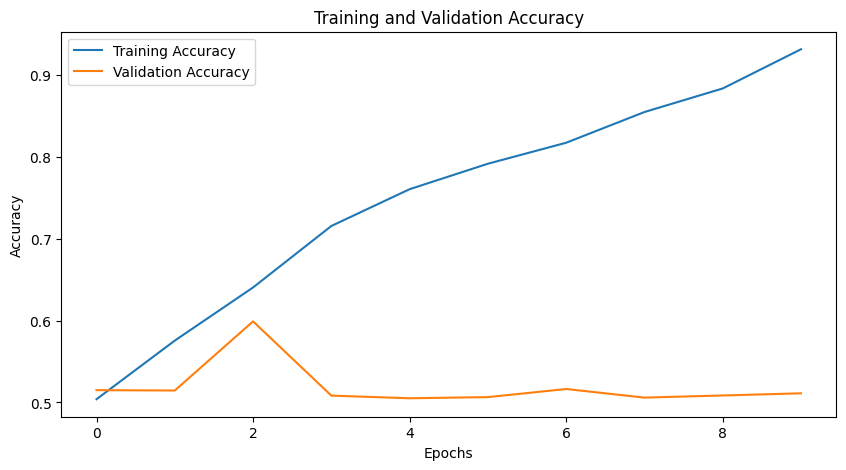

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Step 13: Visualize model loss

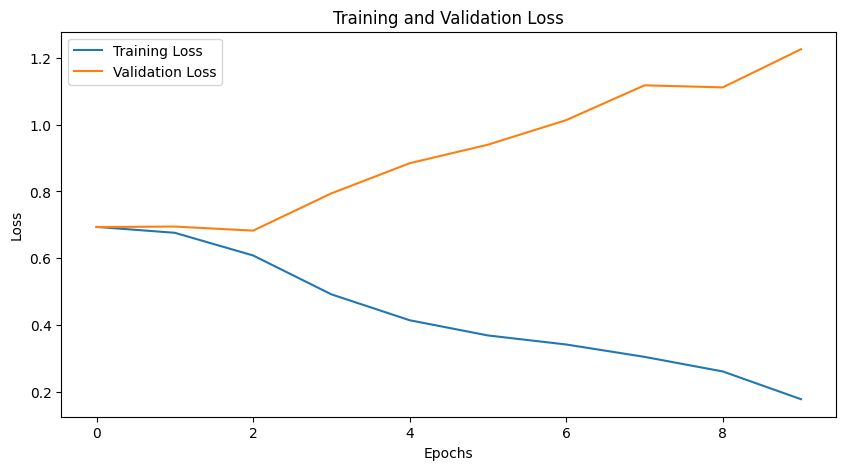

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Step 14: Evaluate the model using test data

In [42]:
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test
)

775/775 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.4979 - loss: 1.2500


In [43]:
print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

print("Test Accuracy Percentage:", test_accuracy * 100)

Test Loss: 1.2500479221343994
Test Accuracy: 0.49788230657577515
Test Accuracy Percentage: 49.788230657577515


Step 15: Make predictions

In [44]:
predictions = model.predict(X_test_padded[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step


In [45]:
for i in range(5):

    predicted_sentiment = (
        "Positive" if predictions[i][0] >= 0.5 else "Negative"
    )

    actual_sentiment = (
        "Positive" if y_test.iloc[i] == 1 else "Negative"
    )

    print("Predicted Sentiment:", predicted_sentiment)
    print("Actual Sentiment:", actual_sentiment)
    print("--------------------------")

Predicted Sentiment: Negative
Actual Sentiment: Negative
--------------------------
Predicted Sentiment: Positive
Actual Sentiment: Positive
--------------------------
Predicted Sentiment: Positive
Actual Sentiment: Negative
--------------------------
Predicted Sentiment: Positive
Actual Sentiment: Negative
--------------------------
Predicted Sentiment: Negative
Actual Sentiment: Negative
--------------------------
